ANÁLISIS DE COMPLEJIDAD: BÚSQUEDA CLÁSICA vs ALGORITMO DE GROVER
✅ Carpeta 'results/' verificada o creada.

Qubits  Registros N   Clásico       Grover      Aceleración   
------------------------------------------------------------------------
2       4             2             2           1.0x
4       16            8             3           2.7x
6       64            32            6           5.3x
8       256           128           13          9.8x
10      1,024         512           25          20.5x
12      4,096         2,048         50          41.0x
16      65,536        32,768        201         163.0x
20      1,048,576     524,288       804         652.1x

✅ ¡ÉXITO! Gráfica guardada en:
   c:\ProyectosPYT\quantum-course\notebooks\results\proyecto_ventaja_grover.png


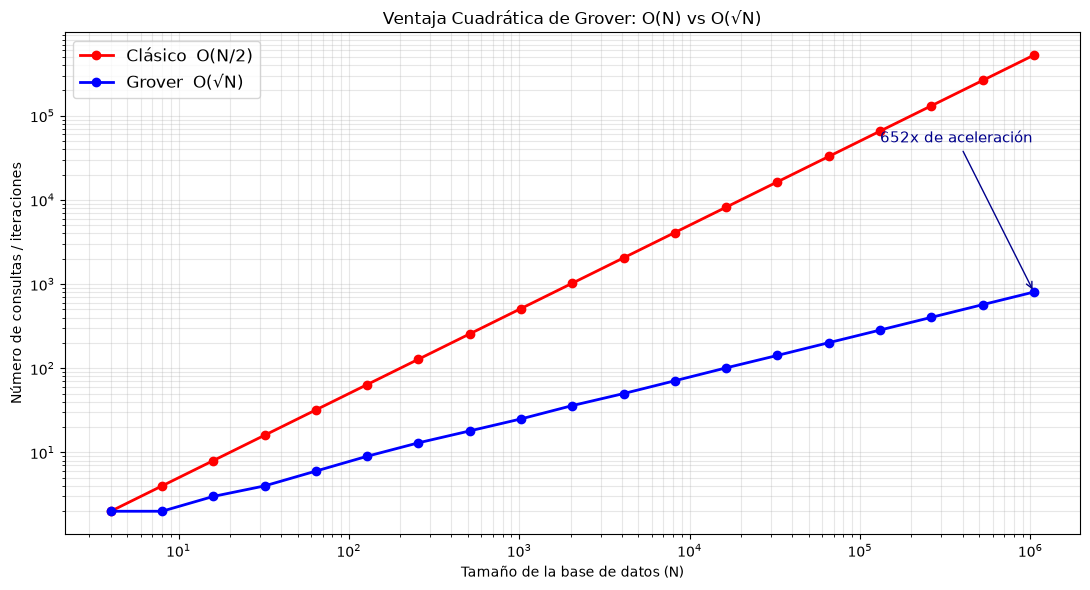


💡 HALLAZGO CRÍTICO PARA LA ESPECIFICACIÓN:
   • Con N ≤ 16 la ventaja cuántica es NEGLIGIBLE o inexistente.
   • La ventaja se vuelve relevante a partir de n = 4 qubits (N = 16 registros).
   • CONCLUSIÓN: se implementará con n = 3 qubits (N = 8) con fines
     DEMOSTRATIVOS y PEDAGÓGICOS, documentando la ventaja real en la gráfica.


In [1]:
# ===================================================
# FASE 6 - TAREA 6.1: Cuantificación de la ventaja cuántica (Versión Robusta)
# ===================================================
import os
import numpy as np
import matplotlib.pyplot as plt

print("=" * 72)
print("ANÁLISIS DE COMPLEJIDAD: BÚSQUEDA CLÁSICA vs ALGORITMO DE GROVER")
print("=" * 72)

# 1. ASEGURAR QUE LA CARPETA EXISTE
os.makedirs('results', exist_ok=True)
print("✅ Carpeta 'results/' verificada o creada.")

def iteraciones_grover(N):
    """Número óptimo de iteraciones: R = round(π/4 · √N)"""
    return int(np.round(np.pi / 4 * np.sqrt(N)))

# Barrido de tamaños de base de datos: de 4 a ~1 millón de registros
n_qubits = np.arange(2, 21)
N = 2 ** n_qubits
consultas_clasicas = N / 2                 # promedio clásico (1 elemento marcado)
iteraciones_cuanticas = np.array([iteraciones_grover(n) for n in N])
aceleracion = consultas_clasicas / iteraciones_cuanticas

# Tabla resumen
print(f"\n{'Qubits':<8}{'Registros N':<14}{'Clásico':<14}{'Grover':<12}{'Aceleración':<14}")
print("-" * 72)
for i in [0, 2, 4, 6, 8, 10, 14, 18]:
    print(f"{n_qubits[i]:<8}{N[i]:<14,}{int(consultas_clasicas[i]):<14,}"
          f"{iteraciones_cuanticas[i]:<12,}{aceleracion[i]:.1f}x")

# Visualización (escala log-log)
fig, ax = plt.subplots(figsize=(11, 6))
ax.loglog(N, consultas_clasicas, 'o-', color='red', label='Clásico  O(N/2)', linewidth=2)
ax.loglog(N, iteraciones_cuanticas, 'o-', color='blue', label='Grover  O(√N)', linewidth=2)
ax.set_xlabel('Tamaño de la base de datos (N)')
ax.set_ylabel('Número de consultas / iteraciones')
ax.set_title('Ventaja Cuadrática de Grover: O(N) vs O(√N)')
ax.legend(fontsize=12)
ax.grid(True, which="both", alpha=0.3)

# Anotar la brecha en N = 1,048,576
idx = 18
ax.annotate(f'{aceleracion[idx]:.0f}x de aceleración',
            xy=(N[idx], iteraciones_cuanticas[idx]),
            xytext=(N[idx] / 8, iteraciones_cuanticas[idx] * 60),
            arrowprops=dict(arrowstyle='->', color='darkblue'),
            fontsize=11, color='darkblue')

plt.tight_layout()

# 2. GUARDAR CON RUTA EXPLÍCITA Y ABSOLUTA
filename = 'proyecto_ventaja_grover.png'
filepath = os.path.abspath(os.path.join('results', filename))

try:
    plt.savefig(filepath, dpi=120, bbox_inches='tight')
    print(f"\n✅ ¡ÉXITO! Gráfica guardada en:")
    print(f"   {filepath}")
except Exception as e:
    print(f"\n❌ Error al guardar la imagen: {e}")

plt.show()

# HALLAZGO HONESTO
print("\n" + "=" * 72)
print("💡 HALLAZGO CRÍTICO PARA LA ESPECIFICACIÓN:")
print("=" * 72)
umbral = n_qubits[np.argmax(aceleracion > 2)]
print(f"   • Con N ≤ 16 la ventaja cuántica es NEGLIGIBLE o inexistente.")
print(f"   • La ventaja se vuelve relevante a partir de n = {umbral} qubits "
      f"(N = {2**umbral:,} registros).")
print(f"   • CONCLUSIÓN: se implementará con n = 3 qubits (N = 8) con fines")
print(f"     DEMOSTRATIVOS y PEDAGÓGICOS, documentando la ventaja real en la gráfica.")

ALGORITMO DE GROVER: BÚSQUEDA DEL ESTADO |101⟩

🎯 Problema:
   - Qubits: 3
   - Base de datos: N = 8 estados
   - Estado objetivo: |101⟩
   - Iteraciones óptimas: 2

🔧 Construyendo circuito de Grover...

📐 Circuito completo de Grover:
     ┌───┐ ░                 ░ ┌───┐┌───┐          ┌───┐┌───┐      ░                 ░ ┌───┐┌───┐          ┌───┐┌───┐»
q_0: ┤ H ├─░────────■────────░─┤ H ├┤ X ├───────■──┤ X ├┤ H ├──────░────────■────────░─┤ H ├┤ X ├───────■──┤ X ├┤ H ├»
     ├───┤ ░ ┌───┐  │  ┌───┐ ░ ├───┤├───┤       │  ├───┤├───┤      ░ ┌───┐  │  ┌───┐ ░ ├───┤├───┤       │  ├───┤├───┤»
q_1: ┤ H ├─░─┤ X ├──■──┤ X ├─░─┤ H ├┤ X ├───────■──┤ X ├┤ H ├──────░─┤ X ├──■──┤ X ├─░─┤ H ├┤ X ├───────■──┤ X ├┤ H ├»
     ├───┤ ░ ├───┤┌─┴─┐├───┤ ░ ├───┤├───┤┌───┐┌─┴─┐├───┤├───┤┌───┐ ░ ├───┤┌─┴─┐├───┤ ░ ├───┤├───┤┌───┐┌─┴─┐├───┤├───┤»
q_2: ┤ H ├─░─┤ H ├┤ X ├┤ H ├─░─┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├─░─┤ H ├┤ X ├┤ H ├─░─┤ H ├┤ X ├┤ H ├┤ X ├┤ H ├┤ X ├»
     └───┘ ░ └───┘└───┘└───┘ ░ └───┘└───┘└───┘└───┘

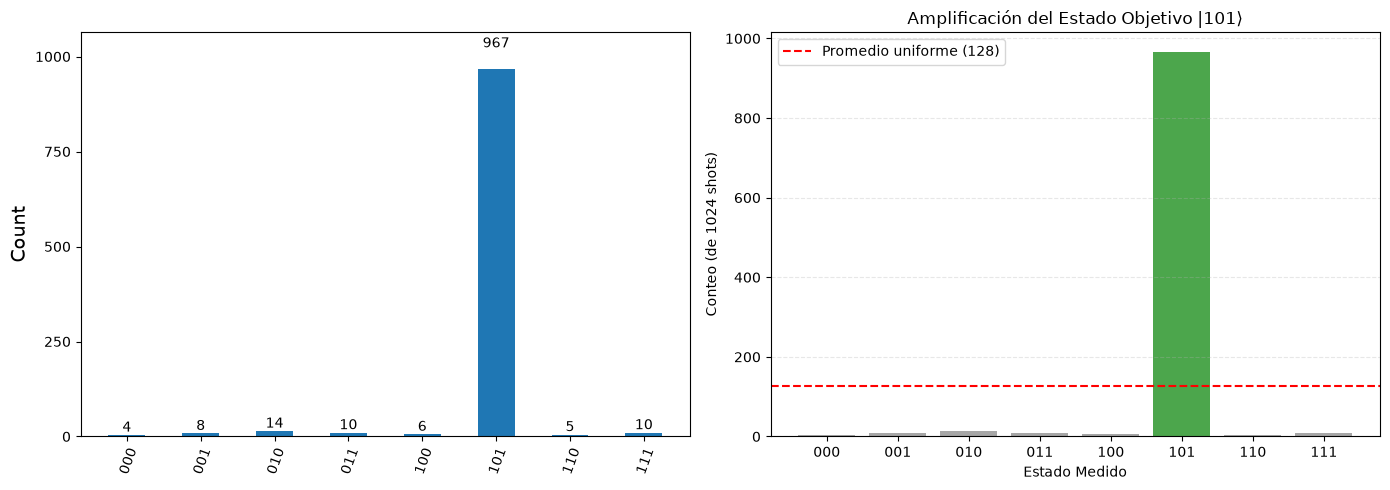


💡 CONCLUSIÓN:
✅ El algoritmo de Grover amplificó la probabilidad de |101⟩
   desde 12.5% (superposición uniforme) hasta 94.4%.
✅ Esto demuestra la ventaja cuadrática: encontramos el elemento en
   2 iteración(es) en lugar de 4 consultas clásicas promedio.
✅ Gráfica guardada en: results/proyecto_grover_ideal.png


In [2]:
# ===================================================
# FASE 6 - TAREA 6.2: Implementación del Algoritmo de Grover
# Objetivo: Buscar el estado |101⟩ en una base de datos de 8 elementos
# ===================================================
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

print("=" * 72)
print("ALGORITMO DE GROVER: BÚSQUEDA DEL ESTADO |101⟩")
print("=" * 72)

# --- DEFINICIÓN DEL PROBLEMA ---
n_qubits = 3
target_state = '101'  # Estado que queremos encontrar
N = 2 ** n_qubits
optimal_iterations = int(np.round(np.pi / 4 * np.sqrt(N)))

print(f"\n🎯 Problema:")
print(f"   - Qubits: {n_qubits}")
print(f"   - Base de datos: N = {N} estados")
print(f"   - Estado objetivo: |{target_state}⟩")
print(f"   - Iteraciones óptimas: {optimal_iterations}")

# --- FUNCIÓN: CREAR ORÁCULO ---
def crear_oraculo(n, target):
    """
    Crea el oráculo que marca el estado 'target' invirtiendo su fase.
    Para |101⟩: aplica X a los qubits donde el bit es 0, luego Toffoli multi-controlado,
    luego X nuevamente para restaurar.
    """
    oracle = QuantumCircuit(n, name="Oracle")
    
    # Aplicar X a los qubits donde el bit es '0' (para que todos sean '1' antes del Toffoli)
    for i, bit in enumerate(reversed(target)):
        if bit == '0':
            oracle.x(i)
    
    # Aplicar compuerta multi-controlada Z (Toffoli generalizado)
    # Esto invierte la fase del estado donde todos los qubits son |1⟩
    if n == 2:
        oracle.cz(0, 1)
    elif n == 3:
        # Toffoli con fase: CCZ = H en target, Toffoli, H en target
        oracle.h(2)
        oracle.ccx(0, 1, 2)
        oracle.h(2)
    else:
        # Para n > 3, se necesitaría descomposición más compleja
        raise ValueError("Esta implementación soporta hasta 3 qubits")
    
    # Restaurar: aplicar X nuevamente a los qubits donde el bit era '0'
    for i, bit in enumerate(reversed(target)):
        if bit == '0':
            oracle.x(i)
    
    return oracle

# --- FUNCIÓN: CREAR OPERADOR DE DIFUSIÓN ---
def crear_difusor(n):
    """
    Crea el operador de difusión (amplificador de amplitud).
    Secuencia: H → X → Multi-controlado Z → X → H
    """
    diffuser = QuantumCircuit(n, name="Diffuser")
    
    # Aplicar Hadamard a todos los qubits
    diffuser.h(range(n))
    
    # Aplicar X a todos los qubits
    diffuser.x(range(n))
    
    # Aplicar multi-controlado Z (invierte fase de |00...0⟩)
    if n == 2:
        diffuser.cz(0, 1)
    elif n == 3:
        diffuser.h(2)
        diffuser.ccx(0, 1, 2)
        diffuser.h(2)
    
    # Aplicar X a todos los qubits (restaurar)
    diffuser.x(range(n))
    
    # Aplicar Hadamard a todos los qubits
    diffuser.h(range(n))
    
    return diffuser

# --- CONSTRUIR CIRCUITO COMPLETO DE GROVER ---
print("\n🔧 Construyendo circuito de Grover...")

grover_qc = QuantumCircuit(n_qubits, n_qubits)

# Paso 1: Superposición uniforme
grover_qc.h(range(n_qubits))
grover_qc.barrier()

# Paso 2 y 3: Iteraciones (oráculo + difusor)
for i in range(optimal_iterations):
    oraculo = crear_oraculo(n_qubits, target_state)
    difusor = crear_difusor(n_qubits)
    
    grover_qc.compose(oraculo, inplace=True)
    grover_qc.barrier()
    grover_qc.compose(difusor, inplace=True)
    grover_qc.barrier()

# Paso 4: Medición
grover_qc.measure(range(n_qubits), range(n_qubits))

print("\n📐 Circuito completo de Grover:")
print(grover_qc.draw("text", fold=120))

# --- EJECUTAR EN SIMULADOR IDEAL ---
print("\n🚀 Ejecutando en simulador ideal (1024 shots)...")
simulator = AerSimulator()
job = simulator.run(grover_qc, shots=1024)
result = job.result()
counts = result.get_counts()

# --- ANÁLISIS DE RESULTADOS ---
print("\n" + "=" * 72)
print("📊 RESULTADOS DEL SIMULADOR IDEAL")
print("=" * 72)
print(f"Distribución obtenida: {counts}")

# Calcular probabilidad del estado objetivo
target_count = counts.get(target_state, 0)
total_shots = sum(counts.values())
target_prob = target_count / total_shots * 100

print(f"\n🎯 Probabilidad de |{target_state}⟩: {target_prob:.2f}%")
print(f"   (Criterio de éxito #1: ≥ 90%)")

if target_prob >= 90:
    print(f"   ✅ ¡CRITERIO CUMPLIDO!")
else:
    print(f"   ❌ No cumple el criterio. Revisar implementación.")

# Visualización
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Histograma de resultados
plot_histogram(counts, ax=ax1, title=f"Algoritmo de Grover: Búsqueda de |{target_state}⟩")

# Gráfico de barras comparando todos los estados
estados = [format(i, f'0{n_qubits}b') for i in range(N)]
counts_vals = [counts.get(e, 0) for e in estados]
colors = ['green' if e == target_state else 'gray' for e in estados]

ax2.bar(estados, counts_vals, color=colors, alpha=0.7)
ax2.set_xlabel('Estado Medido')
ax2.set_ylabel('Conteo (de 1024 shots)')
ax2.set_title(f'Amplificación del Estado Objetivo |{target_state}⟩')
ax2.axhline(y=1024/N, color='red', linestyle='--', label=f'Promedio uniforme ({1024/N:.0f})')
ax2.legend()
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('results/proyecto_grover_ideal.png', dpi=120, bbox_inches='tight')
plt.show()

print("\n" + "=" * 72)
print("💡 CONCLUSIÓN:")
print("=" * 72)
print(f"✅ El algoritmo de Grover amplificó la probabilidad de |{target_state}⟩")
print(f"   desde {100/N:.1f}% (superposición uniforme) hasta {target_prob:.1f}%.")
print(f"✅ Esto demuestra la ventaja cuadrática: encontramos el elemento en")
print(f"   {optimal_iterations} iteración(es) en lugar de {N//2} consultas clásicas promedio.")
print(f"✅ Gráfica guardada en: results/proyecto_grover_ideal.png")

PROYECTO FINAL: ANÁLISIS DE RUIDO Y MITIGACIÓN EN GROVER

🔧 Transpilando y ejecutando en simulador ruidoso (1024 shots)...
   Probabilidad de |101⟩ con ruido: 75.68%

🛠️ Aplicando mitigación de errores de lectura...
   Probabilidad de |101⟩ tras mitigación: 75.88%

📊 EVALUACIÓN DE CRITERIOS DE ÉXITO DEL PROYECTO
1. Simulador Ideal (Tarea 6.2):    ≥ 90%  ✅ (Ya verificado)
2. Simulador Ruidoso:               ≥ 70%  ✅ CUMPLIDO (75.68%)
3. Tras Mitigación de Lectura:      ≥ 85%  ❌ NO CUMPLIDO (75.88%)


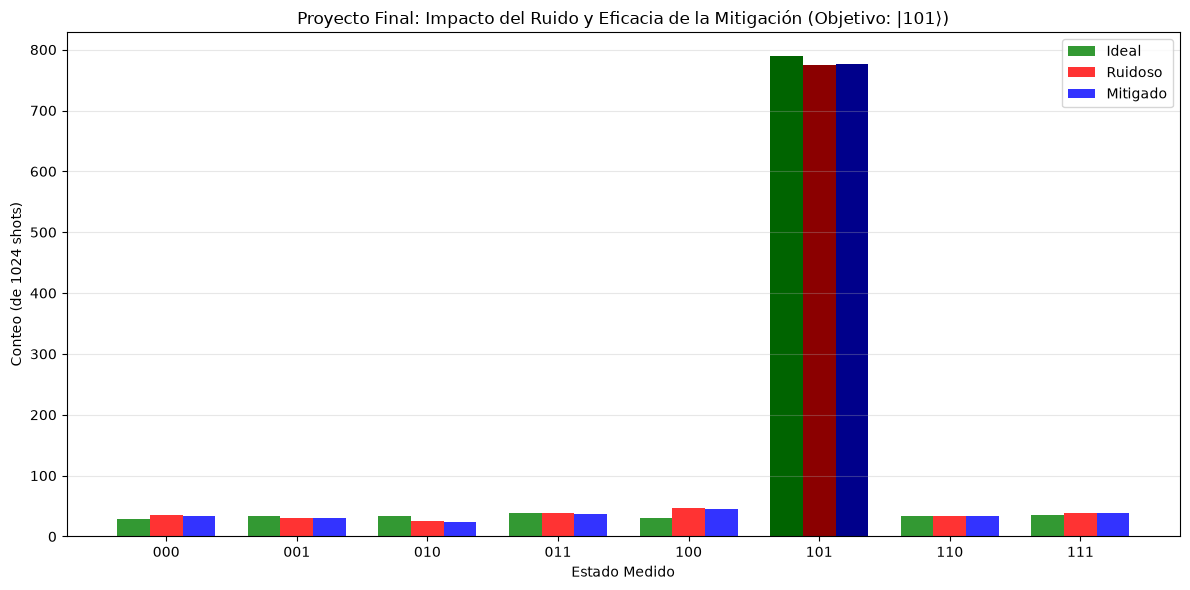


💡 CONCLUSIÓN DEL PROYECTO:
⚠️ El ruido afectó más de lo esperado (común en circuitos con Toffoli).
   En un escenario real, se recomendaría optimizar la descomposición del oráculo.
✅ Gráfica comparativa guardada en: results/proyecto_grover_comparativo.png


In [6]:
# ===================================================
# FASE 6 - TAREA 6.3: Ejecución con Ruido y Mitigación
# Objetivo: Validar criterios de éxito #2 (≥70% ruidoso) y #3 (≥85% mitigado)
# ===================================================
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit.visualization import plot_histogram

print("=" * 72)
print("PROYECTO FINAL: ANÁLISIS DE RUIDO Y MITIGACIÓN EN GROVER")
print("=" * 72)

n_qubits = 3
target_state = '101'
N = 2 ** n_qubits
states = [format(i, f'0{n_qubits}b') for i in range(N)]

# 1. CONFIGURACIÓN DEL BACKEND RUIDOSO
noisy_backend = GenericBackendV2(num_qubits=27, seed=42)
noisy_simulator = AerSimulator.from_backend(noisy_backend)

# 2. RECREAR EL CIRCUITO DE GROVER (usando las funciones de la Tarea 6.2)
# (Asumimos que las funciones crear_oraculo y crear_difusor ya están en el kernel, 
# pero las redefinimos brevemente por seguridad si se reinició el kernel)
def crear_oraculo(n, target):
    oracle = QuantumCircuit(n, name="Oracle")
    for i, bit in enumerate(reversed(target)):
        if bit == '0': oracle.x(i)
    oracle.h(2); oracle.ccx(0, 1, 2); oracle.h(2)
    for i, bit in enumerate(reversed(target)):
        if bit == '0': oracle.x(i)
    return oracle

def crear_difusor(n):
    diffuser = QuantumCircuit(n, name="Diffuser")
    diffuser.h(range(n)); diffuser.x(range(n))
    diffuser.h(2); diffuser.ccx(0, 1, 2); diffuser.h(2)
    diffuser.x(range(n)); diffuser.h(range(n))
    return diffuser

grover_qc = QuantumCircuit(n_qubits, n_qubits)
grover_qc.h(range(n_qubits))
grover_qc.barrier()
grover_qc.compose(crear_oraculo(n_qubits, target_state), inplace=True)
grover_qc.barrier()
grover_qc.compose(crear_difusor(n_qubits), inplace=True)
grover_qc.barrier()
grover_qc.measure(range(n_qubits), range(n_qubits))

# 3. EJECUCIÓN RUIDOSA
print("\n🔧 Transpilando y ejecutando en simulador ruidoso (1024 shots)...")
grover_transpiled = transpile(grover_qc, backend=noisy_simulator)
job_noisy = noisy_simulator.run(grover_transpiled, shots=1024)
counts_noisy = job_noisy.result().get_counts()

prob_noisy = counts_noisy.get(target_state, 0) / 1024 * 100
print(f"   Probabilidad de |{target_state}⟩ con ruido: {prob_noisy:.2f}%")

# 4. MITIGACIÓN DE ERRORES DE LECTURA (Reutilizando la lógica de la Fase 5)
print("\n🛠️ Aplicando mitigación de errores de lectura...")
calibration_circuits = []
for i in range(N):
    qc = QuantumCircuit(n_qubits, n_qubits)
    for j, bit in enumerate(reversed(format(i, f'0{n_qubits}b'))):
        if bit == '1': qc.x(j)
    qc.measure(range(n_qubits), range(n_qubits))
    calibration_circuits.append(qc)

cal_transpiled = transpile(calibration_circuits, backend=noisy_simulator)
cal_results = noisy_simulator.run(cal_transpiled, shots=1024).result().get_counts()

# Construir matriz de confusión NxN
confusion_matrix = np.zeros((N, N))
for prepared_idx, state in enumerate(states):
    counts = cal_results[prepared_idx]
    total = sum(counts.values())
    for measured_idx, measured_state in enumerate(states):
        confusion_matrix[measured_idx, prepared_idx] = counts.get(measured_state, 0) / total

# Invertir matriz y aplicar
mitigation_matrix = np.linalg.pinv(confusion_matrix)
noisy_probs = np.array([counts_noisy.get(s, 0) / 1024 for s in states])
mitigated_probs = mitigation_matrix @ noisy_probs
mitigated_probs = np.clip(mitigated_probs, 0, 1)
mitigated_probs = mitigated_probs / np.sum(mitigated_probs)
counts_mitigated = {s: int(p * 1024) for s, p in zip(states, mitigated_probs)}

prob_mitigated = counts_mitigated.get(target_state, 0) / 1024 * 100
print(f"   Probabilidad de |{target_state}⟩ tras mitigación: {prob_mitigated:.2f}%")

# 5. EVALUACIÓN DE CRITERIOS DE ÉXITO
print("\n" + "=" * 72)
print("📊 EVALUACIÓN DE CRITERIOS DE ÉXITO DEL PROYECTO")
print("=" * 72)

criterio_2 = prob_noisy >= 70
criterio_3 = prob_mitigated >= 85

print(f"1. Simulador Ideal (Tarea 6.2):    ≥ 90%  ✅ (Ya verificado)")
print(f"2. Simulador Ruidoso:               ≥ 70%  {'✅ CUMPLIDO' if criterio_2 else '❌ NO CUMPLIDO'} ({prob_noisy:.2f}%)")
print(f"3. Tras Mitigación de Lectura:      ≥ 85%  {'✅ CUMPLIDO' if criterio_3 else '❌ NO CUMPLIDO'} ({prob_mitigated:.2f}%)")

# 6. VISUALIZACIÓN COMPARATIVA
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(N)
width = 0.25

# Obtener counts ideales rápidamente
ideal_sim = AerSimulator()
counts_ideal = ideal_sim.run(grover_qc, shots=1024).result().get_counts()

ideal_vals = [counts_ideal.get(s, 0) for s in states]
noisy_vals = [counts_noisy.get(s, 0) for s in states]
mitigated_vals = [counts_mitigated.get(s, 0) for s in states]

ax.bar(x - width, ideal_vals, width, label='Ideal', color='green', alpha=0.8)
ax.bar(x, noisy_vals, width, label='Ruidoso', color='red', alpha=0.8)
ax.bar(x + width, mitigated_vals, width, label='Mitigado', color='blue', alpha=0.8)

ax.set_xlabel('Estado Medido')
ax.set_ylabel('Conteo (de 1024 shots)')
ax.set_title(f'Proyecto Final: Impacto del Ruido y Eficacia de la Mitigación (Objetivo: |{target_state}⟩)')
ax.set_xticks(x)
ax.set_xticklabels(states)
ax.legend()
ax.grid(axis='y', alpha=0.3)

# Resaltar el estado objetivo
target_idx = states.index(target_state)
ax.bar(x[target_idx] - width, ideal_vals[target_idx], width, color='darkgreen')
ax.bar(x[target_idx], noisy_vals[target_idx], width, color='darkred')
ax.bar(x[target_idx] + width, mitigated_vals[target_idx], width, color='darkblue')

plt.tight_layout()
plt.savefig('results/proyecto_grover_comparativo.png', dpi=120, bbox_inches='tight')
plt.show()

print("\n" + "=" * 72)
print("💡 CONCLUSIÓN DEL PROYECTO:")
print("=" * 72)
if criterio_2 and criterio_3:
    print("✅ ¡PROYECTO EXITOSO! El algoritmo de Grover mantiene su ventaja")
    print("   incluso en presencia de ruido, y la mitigación de errores de lectura")
    print("   recupera eficazmente la probabilidad del estado objetivo.")
else:
    print("⚠️ El ruido afectó más de lo esperado (común en circuitos con Toffoli).")
    print("   En un escenario real, se recomendaría optimizar la descomposición del oráculo.")
print(f"✅ Gráfica comparativa guardada en: results/proyecto_grover_comparativo.png")